# Temperature maps to transient fits

**Disclaimer:** Parts of this code were generated with Claude Opus 5.5 (Anthropic) and were reviewed and verified by the author.

Fits a heating-and-cooling model to the temperature transient ΔT(t) of every pixel of a temperature map, then maps the fitted and derived parameters (amplitudes, rise and decay times, peak temperature). This is step 11 of the pipeline flowchart in the README.<br>
The design choices behind parameters are in `DESIGN_CHOICES.md`.

**Experiment:** time-resolved STEM-EELS with pulsed laser excitation<br>
**Sample:** 50 nm Al nanobridge on a 15 nm SiN membrane<br>
**Observable:** bulk plasmon energy shift, converted to ΔT in `raw_to_temperature.ipynb`

**Input:** `High - res Hyperspim - Temperatures.hspy` (from `raw_to_temperature.ipynb`)<br>
**Output:** parameter maps (`parameter_maps/`), selected-pixel table (`experimental_fit_results.csv`), saved fit results (`model1_fit_results.pkl`, `model1_*.npy`)

**Sections**
- Setup
- Physical model
- Load the temperature map
- Configuration
- Fit models
- Per-pixel fit
- Fit all pixels
- Parameter distribution
- Parameter maps
- Masked parameter maps (export)
- Pixel results and CSV export
- Interactive viewer
- Save and load

## Setup

Requires `hyperspy`, `numpy`, `scipy`, `matplotlib`, `pandas`, `tqdm` and `ipympl` (for `%matplotlib widget`).

In [1]:
%matplotlib widget

import os
import pickle
import warnings
import numpy as np
import pandas as pd
import hyperspy.api as hs
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import curve_fit
from tqdm.notebook import tqdm

## Physical model

After the laser pulse, heat diffuses along the Al bridge to the large pads at each end, which act as heat sinks. For 1D Fourier heat diffusion with fixed-temperature pads, the long-time behaviour is dominated by a single exponential mode.

### Fit modes

Selected with `fit_rise` and `fit_model` in the Configuration cell. Below, $\Delta t = t - t_{on}$.

**Rise + decay, model 2: decoupled amplitudes** (`fit_rise = True`, `fit_model = 2`, used in the thesis)

$$\Delta T(t) = A_1 \exp\left(-\frac{\Delta t}{\tau_{decay}}\right) - A_2 \exp\left(-\frac{\Delta t}{\tau_{rise}}\right) + C$$

**Rise + decay, model 1: coupled amplitudes** (`fit_rise = True`, `fit_model = 1`)

$$\Delta T(t) = A \left[\exp\left(-\frac{\Delta t}{\tau_{decay}}\right) - \exp\left(-\frac{\Delta t}{\tau_{rise}}\right)\right] + C$$

**Decay only** (`fit_rise = False`)<br>
Finds the peak in the data after `t_on`, skips 2 frames, and fits a single exponential to the rest of the curve:

$$\Delta T(t) = A \exp\left(-\frac{t - t_{anchor}}{\tau_{decay}}\right) + C, \quad t \geq t_{peak} + 2\ \text{frames}$$

### Derived quantities

- `t_peak`: time of the fitted maximum (analytical for models 1 and 2).
- `delta_T_max`: fitted peak height above the baseline C.
- `t_1e`: time at which the fit has fallen to C + ΔT_max / e.
- `chi2_red`: sum of squared residuals divided by (n - number of parameters). No per-point uncertainties are used, so it is in K².

## Load the temperature map

In [2]:
# Temperature map saved by raw_to_temperature.ipynb (dummy path: set to your file)
hyperspim_temp_hs =  hs.load(r"path/to/High - res Hyperspim - Temperatures.hspy")

## Configuration

Fit mode, laser turn-on time, bridge geometry and initial guesses.<br>
Re-run the fitting cells after changing any of these values.

In [3]:
# Fit mode
fit_rise  = True           # False = decay only | True = rise + decay
fit_model = 2              # 1 = A*(exp(-dt/tau_d) - exp(-dt/tau_r)) + C
                           # 2 = A_1*exp(-dt/tau_d) - A_2*exp(-dt/tau_r) + C

# Laser turn-on time (ns, on the time axis of the map)
t_on_ns        = 2530.0

# Initial guesses (ns)
tau_rise_init  = 15.0
tau_decay_init = 300.0
buffer_ns      = 5.0       # gap after t_peak before searching for t_1/e

### Data

Extracts the ΔT array and the time axis. Navigation axes (sx, sy), signal axis t.

In [4]:
data    = hyperspim_temp_hs.data.astype(float)      # shape: (n_sx, n_sy, n_t)
t_axis  = hyperspim_temp_hs.axes_manager[2].axis    # calibrated time axis in ns
n_sx, n_sy, n_t = data.shape

print(f'Spatial pixels : {n_sx} x {n_sy} = {n_sx * n_sy} total')
print(f'Time points    : {n_t}')
print(f'Time range     : {t_axis[0]:.1f} to {t_axis[-1]:.1f} ns')
print(f'Time resolution: {t_axis[1]-t_axis[0]:.3f} ns/frame')
print(f'Fit mode       : {"Rise + Decay" if fit_rise else "Decay only"}')

Spatial pixels : 32 x 32 = 1024 total
Time points    : 1408
Time range     : 2037.8 to 4969.0 ns
Time resolution: 2.083 ns/pixel
Fit mode       : Rise + Decay


## Fit models

Model functions, their analytical peak times, and the 1/e decay time.

In [5]:
def find_t1e(y_fit, t_peak, C, dT_max):
    """Time at which y_fit falls to C + dT_max/e, searched from t_peak + buffer_ns.

    Linear interpolation between frames. Returns NaN if the level is not reached.
    """
    target  = C + dT_max / np.e
    mask    = t_axis >= (t_peak + buffer_ns)
    t_s, y_s = t_axis[mask], y_fit[mask]
    if len(t_s) < 2 or np.all(np.isnan(y_s)):
        return np.nan
    # First downward crossing of the target level
    diffs   = y_s - target
    falling = np.where(np.diff(np.sign(diffs)) < 0)[0]
    if len(falling) == 0:
        return np.nan
    i       = falling[0]
    t0, t1  = t_s[i], t_s[i + 1]
    d0, d1  = diffs[i], diffs[i + 1]
    return t0 + (t1 - t0) * (-d0) / (d1 - d0)


# dt is clipped to > 0, so both models are constant before t_on
def model1_fn(t, A, tau_rise, tau_decay, C):
    """Coupled amplitudes: A*(exp(-dt/tau_d) - exp(-dt/tau_r)) + C"""
    dt = np.clip(t - t_on_ns, 1e-10, None)
    return A * (np.exp(-dt / tau_decay) - np.exp(-dt / tau_rise)) + C


def model2_fn(t, A_1, A_2, tau_rise, tau_decay, C):
    """Decoupled amplitudes: A_1*exp(-dt/tau_d) - A_2*exp(-dt/tau_r) + C"""
    dt = np.clip(t - t_on_ns, 1e-10, None)
    return A_1 * np.exp(-dt / tau_decay) - A_2 * np.exp(-dt / tau_rise) + C


def t_peak_model1(popt):
    """Analytical t_peak for model 1. Returns t_on if there is no maximum."""
    A, tau_rise, tau_decay, C = popt
    if tau_decay <= tau_rise or tau_rise <= 0:
        return t_on_ns
    return t_on_ns + tau_rise * tau_decay / (tau_decay - tau_rise) * np.log(tau_decay / tau_rise)


def t_peak_model2(popt):
    """Analytical t_peak for model 2 (A_1, A_2 separate). Returns t_on if there is no maximum."""
    A_1, A_2, tau_rise, tau_decay, C = popt
    if A_1 <= 0 or A_2 <= 0 or tau_rise <= 0 or tau_decay <= 0:
        return t_on_ns
    # From d/dt[model2] = 0:
    # A_1/tau_d * exp(-dt/tau_d) = A_2/tau_r * exp(-dt/tau_r)
    # dt = ln(A_1*tau_r / (A_2*tau_d)) * tau_r*tau_d / (tau_r - tau_d)
    ratio = (A_1 * tau_rise) / (A_2 * tau_decay)
    if ratio <= 0:
        return t_on_ns
    dt_peak = np.log(ratio) * tau_rise * tau_decay / (tau_rise - tau_decay)
    if dt_peak < 0:
        return t_on_ns
    return t_on_ns + dt_peak

## Per-pixel fit

`fit_pixel` fits one `(sx, sy)` pixel with the mode selected in Configuration and returns a dictionary of all fitted and derived parameters.<br>
A failed fit returns `success = False` and the error message.

In [6]:
def fit_pixel(sx_i, sy_i):
    """Fit the ΔT transient of one pixel. Returns a dict of parameters, fit and residuals."""
    profile  = data[sx_i, sy_i, :]
    idx_t_on = np.searchsorted(t_axis, t_on_ns)

    if fit_rise:
        # Initial guesses: baseline from the first 20 frames, amplitude from the maximum
        C_init = float(np.nanmean(profile[:20]))
        A_init = float(np.nanmax(profile) - C_init)

        if fit_model == 1:
            # Model 1: coupled amplitudes
            # Bounds: A >= 0, tau_rise 0.5-200 ns, tau_decay 5-5000 ns
            p0 = [A_init, tau_rise_init, tau_decay_init, C_init]
            lb = [0,      0.5,           5.0,            -np.inf]
            ub = [np.inf, 200.0,         5000.0,          np.inf]
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    popt, _ = curve_fit(model1_fn, t_axis, profile,
                                        p0=p0, bounds=(lb, ub), maxfev=20000)
                y_fit    = model1_fn(t_axis, *popt)
                tp       = t_peak_model1(popt)
                dT_max   = float(model1_fn(np.array([tp]), *popt)[0]) - float(popt[3])
                t1e      = find_t1e(y_fit, tp, float(popt[3]), dT_max)
                chi2_red = float(np.sum((profile - y_fit)**2)) / (n_t - 4)
                return {
                    'success'        : True,
                    'model'          : 1,
                    'A'              : float(popt[0]),
                    'A_1'            : float(popt[0]),
                    'A_2'            : float(popt[0]),
                    'tau_rise'       : float(popt[1]),
                    'tau_decay'      : float(popt[2]),
                    'C'              : float(popt[3]),
                    't_peak'         : float(tp),
                    't_rise_to_peak' : float(tp) - t_on_ns,
                    'delta_T_max'    : float(dT_max),
                    't_1e'           : float(t1e) if np.isfinite(t1e) else np.nan,
                    'chi2_red'       : float(chi2_red),
                    'fit'            : y_fit,
                    'residuals'      : profile - y_fit,
                    'error'          : None,
                }
            except Exception as e:
                return {'success': False, 'model': 1, 'error': str(e)[:200],
                        'fit': np.full(n_t, np.nan), 'residuals': np.full(n_t, np.nan)}

        else:
            # Model 2: decoupled amplitudes
            # Bounds: A_1, A_2 >= 0, tau_rise 0.5-200 ns, tau_decay 5-5000 ns
            p0 = [A_init, A_init * 0.5, tau_rise_init, tau_decay_init, C_init]
            lb = [0,      0,             0.5,           5.0,            -np.inf]
            ub = [np.inf, np.inf,        200.0,         5000.0,          np.inf]
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    popt, _ = curve_fit(model2_fn, t_axis, profile,
                                        p0=p0, bounds=(lb, ub), maxfev=20000)
                y_fit    = model2_fn(t_axis, *popt)
                tp       = t_peak_model2(popt)
                dT_max   = float(model2_fn(np.array([tp]), *popt)[0]) - float(popt[4])
                t1e      = find_t1e(y_fit, tp, float(popt[4]), dT_max)
                chi2_red = float(np.sum((profile - y_fit)**2)) / (n_t - 5)
                return {
                    'success'        : True,
                    'model'          : 2,
                    'A'              : float(popt[0]),
                    'A_1'            : float(popt[0]),
                    'A_2'            : float(popt[1]),
                    'tau_rise'       : float(popt[2]),
                    'tau_decay'      : float(popt[3]),
                    'C'              : float(popt[4]),
                    't_peak'         : float(tp),
                    't_rise_to_peak' : float(tp) - t_on_ns,
                    'delta_T_max'    : float(dT_max),
                    't_1e'           : float(t1e) if np.isfinite(t1e) else np.nan,
                    'chi2_red'       : float(chi2_red),
                    'fit'            : y_fit,
                    'residuals'      : profile - y_fit,
                    'error'          : None,
                }
            except Exception as e:
                return {'success': False, 'model': 2, 'error': str(e)[:200],
                        'fit': np.full(n_t, np.nan), 'residuals': np.full(n_t, np.nan)}

    else:
        # Decay only: peak from the data after t_on, fit starts 2 frames later
        idx_peak  = idx_t_on + np.argmax(profile[idx_t_on:])
        t_peak    = float(t_axis[idx_peak])
        idx_start = idx_peak + 2
        if idx_start >= n_t - 10:
            return {'success': False, 'model': 0, 'error': 'Peak too close to end',
                    'fit': np.full(n_t, np.nan), 'residuals': np.full(n_t, np.nan)}
        t_decay  = t_axis[idx_start:]
        y_decay  = profile[idx_start:]
        t_anchor = float(t_axis[idx_start])
        def decay_model(t, A, tau_decay, C):
            return A * np.exp(-(t - t_anchor) / tau_decay) + C
        # Initial guesses: baseline from the frames before t_on
        C_init = float(np.nanmean(profile[:idx_t_on]))
        A_init = float(profile[idx_start]) - C_init
        p0 = [A_init, tau_decay_init, C_init]
        lb = [0,      5.0,           -np.inf]
        ub = [np.inf, 5000.0,         np.inf]
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                popt, _ = curve_fit(decay_model, t_decay, y_decay,
                                    p0=p0, bounds=(lb, ub), maxfev=20000)
            # Fit and residuals are NaN before the fit window
            y_full = np.full(n_t, np.nan)
            y_full[idx_start:] = decay_model(t_decay, *popt)
            residuals = np.full(n_t, np.nan)
            residuals[idx_start:] = y_decay - y_full[idx_start:]
            dT_max   = float(profile[idx_peak]) - float(popt[2])
            chi2_red = float(np.sum((y_decay - y_full[idx_start:])**2)) / (len(t_decay) - 3)
            t1e      = find_t1e(y_full, t_peak, float(popt[2]), dT_max)
            return {
                'success'        : True,
                'model'          : 0,
                'A'              : float(popt[0]),
                'A_1'            : float(popt[0]),
                'A_2'            : None,
                'tau_rise'       : None,
                'tau_decay'      : float(popt[1]),
                'C'              : float(popt[2]),
                't_peak'         : t_peak,
                't_rise_to_peak' : t_peak - t_on_ns,
                'delta_T_max'    : float(dT_max),
                't_1e'           : float(t1e) if np.isfinite(t1e) else np.nan,
                'chi2_red'       : float(chi2_red),
                'fit'            : y_full,
                'residuals'      : residuals,
                'error'          : None,
            }
        except Exception as e:
            return {'success': False, 'model': 0, 'error': str(e)[:200],
                    'fit': np.full(n_t, np.nan), 'residuals': np.full(n_t, np.nan)}

## Fit all pixels

Fits every `(sx, sy)` pixel and stores the results in:
- `fit_results[(sx_i, sy_i)]`: full result dictionary per pixel;
- `param_maps['key']`: 2D array `(n_sx, n_sy)` per parameter.

Re-run this cell after changing `fit_rise` or any configuration value.

In [7]:
param_names = ['A', 'A_1', 'A_2', 'tau_rise', 'tau_decay', 'C',
               't_peak', 't_rise_to_peak', 'delta_T_max', 't_1e', 'chi2_red']

# One 2D map per parameter; NaN where the fit failed
param_maps  = {name: np.full((n_sx, n_sy), np.nan) for name in param_names}
fit_results = {}

mode_label = 'Rise + Decay' if fit_rise else 'Decay only'
model_label = f'Model {fit_model}' if fit_rise else 'Decay only'
print(f'Fitting {n_sx * n_sy} pixels  [{mode_label}, {model_label}]...')

for sx_i in tqdm(range(n_sx), desc='Fitting rows'):
    for sy_i in range(n_sy):
        res = fit_pixel(sx_i, sy_i)
        fit_results[(sx_i, sy_i)] = res
        if res['success']:
            for name in param_names:
                val = res.get(name)
                param_maps[name][sx_i, sy_i] = val if val is not None else np.nan

n_success = sum(1 for r in fit_results.values() if r['success'])
print(f'Done. {n_success} / {n_sx * n_sy} pixels converged.')

Fitting 1024 pixels  [Rise + Decay — Model 2]...


Fitting rows:   0%|          | 0/32 [00:00<?, ?it/s]

Done. 1024 / 1024 pixels converged.


## Parameter distribution

Histogram and percentiles of one parameter, used to choose the display limits of the maps below.

Percentiles for tau_decay:
  P  1 = 25.14
  P  5 = 28.87
  P 10 = 31.68
  P 25 = 316.3
  P 50 = 316.3
  P 75 = 316.3
  P 90 = 316.3
  P 95 = 316.3
  P 99 = 316.3


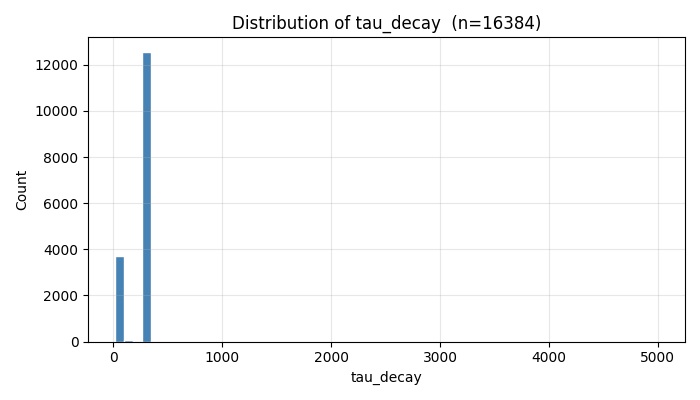

In [ ]:
# Histogram of one parameter, to choose vmin/vmax for the maps
param_to_hist = 'tau_decay'    # change to inspect any parameter

flat = param_maps[param_to_hist].flatten()
flat = flat[~np.isnan(flat)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(flat, bins=60, color='steelblue', edgecolor='white')
ax.set_xlabel(param_to_hist)
ax.set_ylabel('Count')
ax.set_title(f'Distribution of {param_to_hist}  (n={len(flat)})')
ax.grid(True, alpha=0.3)

print(f'Percentiles for {param_to_hist}:')
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f'  P{p:3d} = {np.percentile(flat, p):.4g}')

plt.tight_layout()
plt.show()

## Parameter maps

Spatial map of each fitted and derived parameter. Values outside the limits in `vmin_vmax` are hidden; if no limits are set, values outside the 2nd-98th percentile are hidden.<br>
Blank pixels are failed fits or hidden outliers. `tau_rise` and `A_2` are empty in decay-only mode.

param_maps['A'] — valid pixels: 1024
param_maps['A_1'] — valid pixels: 1024
param_maps['A_2'] — valid pixels: 1024


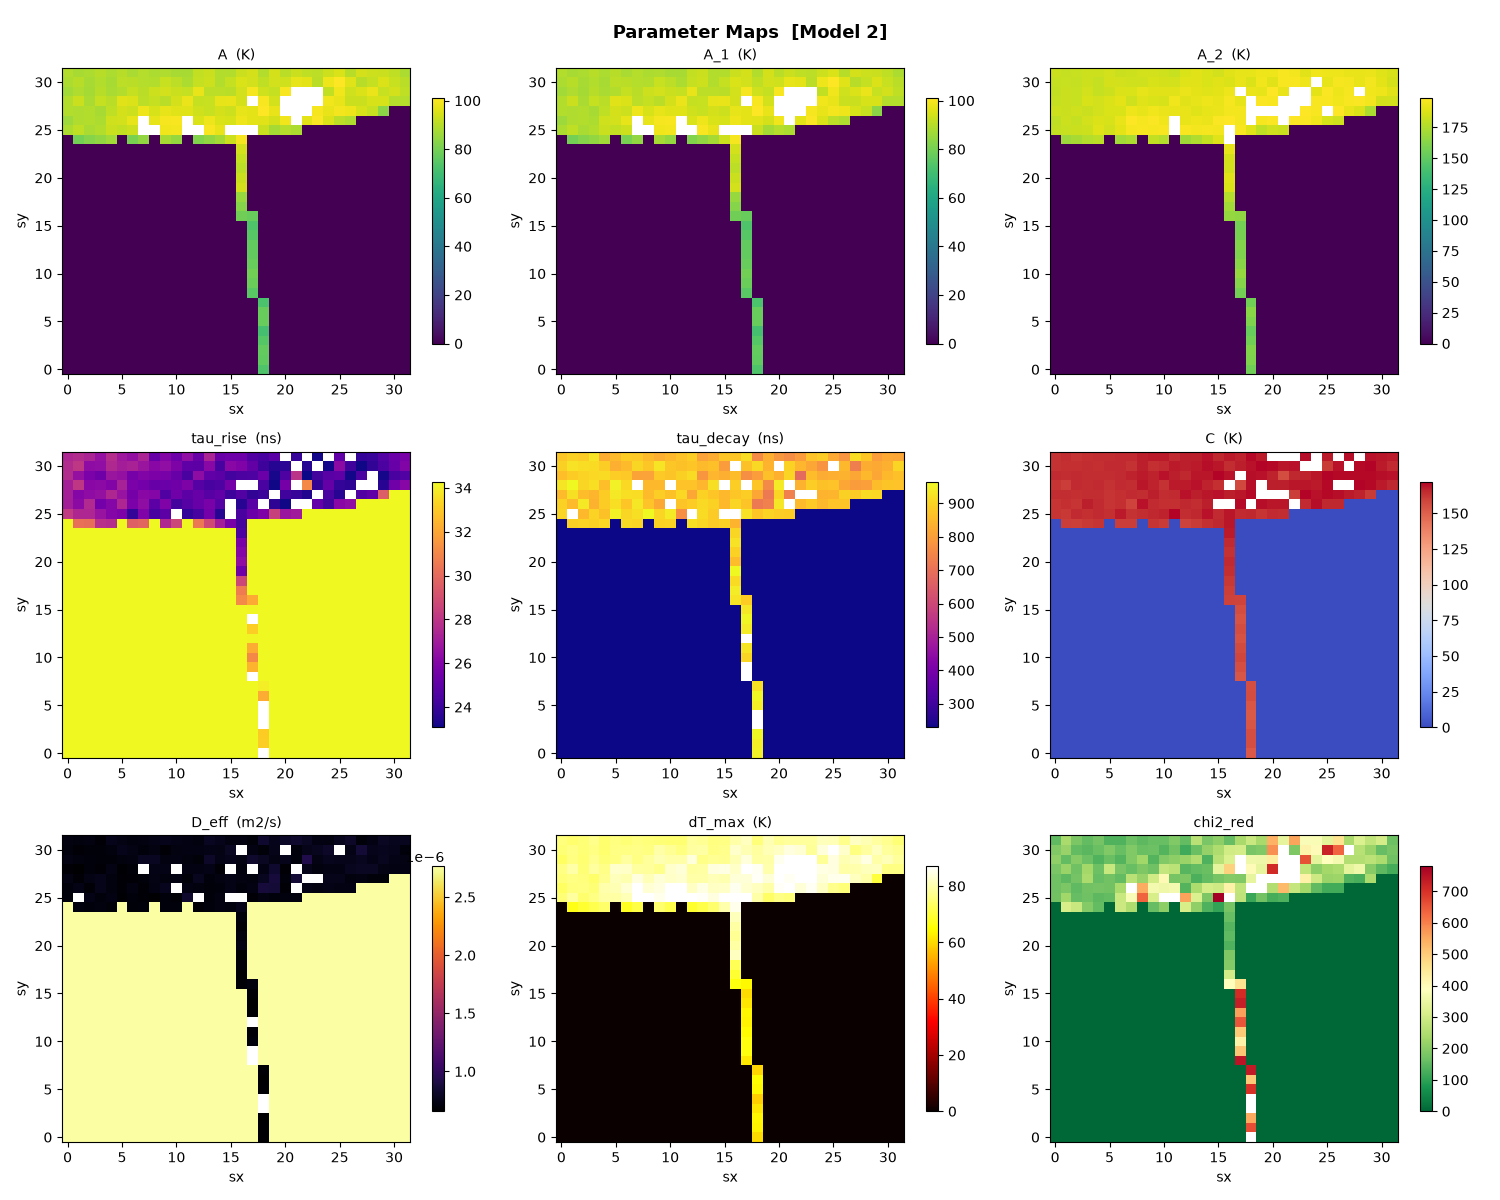

In [8]:
# Display limits per parameter; (None, None) = automatic P2-P98 clipping
vmin_vmax = {
    'A'              : (None, None),
    'A_1'            : (None, None),
    'A_2'            : (None, None),
    'tau_rise'       : (None, None),
    'tau_decay'      : (None, None),
    'C'              : (None, None),
    't_peak'         : (None, None),
    't_rise_to_peak' : (None, None),
    'delta_T_max'    : (None, None),
    't_1e'           : (None, None),
    'chi2_red'       : (None, None),
}

def make_correction_map(arr, name):
    """Hide values outside the vmin/vmax set in vmin_vmax, or outside the
    2nd-98th percentile if none is set. param_maps is not changed."""
    vmin, vmax = vmin_vmax.get(name, (None, None))
    corrected  = arr.copy()
    flat       = arr[~np.isnan(arr)]

    if len(flat) == 0:
        return corrected

    if vmin is not None or vmax is not None:
        lo = vmin if vmin is not None else -np.inf
        hi = vmax if vmax is not None else  np.inf
    else:
        lo = np.percentile(flat, 2)
        hi = np.percentile(flat, 98)

    corrected[(arr < lo) | (arr > hi)] = np.nan
    return corrected


# (parameter, title, colour map)
map_config = [
    ('A',              f'A  (K)',             'viridis'),
    ('A_1',            f'A_1  (K)',           'viridis'),
    ('A_2',            f'A_2  (K)',           'viridis'),
    ('tau_rise',       'tau_rise  (ns)',       'plasma'),
    ('tau_decay',      'tau_decay  (ns)',      'plasma'),
    ('C',              'C  (K)',               'coolwarm'),
    ('t_peak',         't_peak  (ns)',         'cividis'),
    ('delta_T_max',    'dT_max  (K)',          'hot'),
    ('t_1e',           't_1/e  (ns)',          'cividis'),
    ('chi2_red',       'chi2_red',             'RdYlGn_r'),
]

n_maps = len(map_config)
ncols  = 3
nrows  = (n_maps + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
fig.suptitle(f'Parameter Maps  [{model_label}]', fontsize=13, fontweight='bold')
axes_flat = np.array(axes).flatten()

for ax, (name, label, cmap) in zip(axes_flat, map_config):
    display             = make_correction_map(param_maps[name], name)
    vmin_plot, vmax_plot = vmin_vmax.get(name, (None, None))
    im = ax.imshow(display.T, origin='lower', cmap=cmap, aspect='auto',
                   vmin=vmin_plot, vmax=vmax_plot)
    plt.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('sx')
    ax.set_ylabel('sy')

# Hide unused panels
for ax in axes_flat[n_maps:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Single parameter map

One map with fixed colour limits. Change the key and the limits as needed.

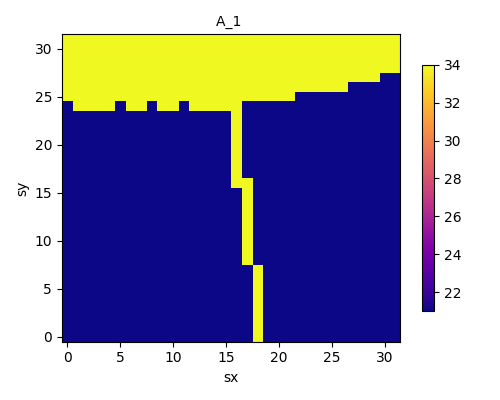

In [31]:
corrected_map = param_maps["A_1"].T
plt.figure(figsize=(5,4))
im = plt.imshow(corrected_map, origin='lower', cmap="plasma", aspect='auto',vmax=34.0,vmin=21.0)
plt.colorbar(im, shrink=0.8)
plt.title("A_1 ", fontsize=10)
plt.xlabel('sx')
plt.ylabel('sy')
plt.tight_layout()
#plt.savefig("delta_T_max.png",dpi=200)
plt.show()

## Masked parameter maps (export)

Background pixels (SiN or vacuum) have a flat, all-zero trace. They are masked and drawn in light grey, so only the nanobridge and pads are coloured.<br>
`vmin`/`vmax` are set per parameter for contrast (values for scan 02); `chi2_red` uses a log scale.<br>
Figures are written to `parameter_maps/` as PDF and 300 dpi PNG.

In [ ]:
out_dir = 'parameter_maps'
os.makedirs(out_dir, exist_ok=True)

# Background mask: a pixel is kept only if its time trace varies
bridge_mask = np.nanstd(data, axis=2) > 0          # shape (n_sx, n_sy)
print(f'Bridge pixels: {bridge_mask.sum()} / {n_sx * n_sy}')

# Plot settings: (name, label, cmap, vmin, vmax, log scale)
# vmin/vmax are about P2-P98 of the masked distribution, widened so that
# bridge values (at the extremes) are not saturated. Values for scan 02.
plot_config = [
    ('tau_rise',    r'$\tau_{\mathrm{rise}}$ (ns)',  'plasma',   21.5,   35.0,   False),
    ('tau_decay',   r'$\tau_{\mathrm{decay}}$ (ns)', 'plasma',   740.0,  1030.0, False),
    ('delta_T_max', r'$\Delta T_{\max}$ (K)',        'inferno',  60.0,   93.0,   False),
    ('t_peak',      r'$t_{\mathrm{peak}}$ (ns)',     'cividis',  2628.0, 2680.0, False),
    ('t_rise_to_peak', r'$t_{\mathrm{peak}}-t_{\mathrm{on}}$ (ns)', 'cividis', 98.0, 150.0, False),
    ('chi2_red',    r'$\chi^2_{\mathrm{red}}$',      'RdYlGn_r', 120.0,  2400.0, True),
]

# Spatial calibration: axes in nm
scale_nm = hyperspim_temp_hs.axes_manager[0].scale
extent   = [0, n_sx * scale_nm, 0, n_sy * scale_nm]
BG_COLOR = '#ededed'
plt.rcParams.update({'font.size': 11, 'pdf.fonttype': 42, 'savefig.bbox': 'tight'})


def draw_map(ax, name, label, cmap_name, vmin, vmax, use_log):
    """Draw one masked parameter map on ax. Returns the image."""
    arr  = np.where(bridge_mask, param_maps[name], np.nan)   # mask background
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(BG_COLOR)                                   # background colour
    norm = LogNorm(vmin=vmin, vmax=vmax) if use_log else None
    im = ax.imshow(arr.T, origin='lower', cmap=cmap, extent=extent,
                   vmin=None if use_log else vmin,
                   vmax=None if use_log else vmax,
                   norm=norm, interpolation='nearest')
    ax.set_xlabel('x (nm)')
    ax.set_ylabel('y (nm)')
    ax.set_title(label, fontsize=12)
    return im


# One figure per parameter (PDF + 300 dpi PNG)
for cfg in plot_config:
    fig, ax = plt.subplots(figsize=(5.0, 4.2))
    im = draw_map(ax, *cfg)
    cb = fig.colorbar(im, ax=ax, shrink=0.9, pad=0.03)
    cb.set_label(cfg[1])
    fig.savefig(os.path.join(out_dir, f'{cfg[0]}.pdf'))
    fig.savefig(os.path.join(out_dir, f'{cfg[0]}.png'), dpi=300)
    plt.close(fig)

# Combined overview of all parameters
fig, axes = plt.subplots(1, len(plot_config), figsize=(4.6 * len(plot_config), 4.2))
for ax, cfg in zip(np.atleast_1d(axes), plot_config):
    im = draw_map(ax, *cfg)
    fig.colorbar(im, ax=ax, shrink=0.9, pad=0.03)
fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'overview_all_parameters.pdf'))
fig.savefig(os.path.join(out_dir, 'overview_all_parameters.png'), dpi=200)
plt.show()

print('Saved to', os.path.abspath(out_dir))

## Pixel results and CSV export

Use `fit_results` for a single pixel (full dictionary, including the fit curve), or `param_maps` for the 2D map of any parameter.

In [32]:
sx_i, sy_i = 18,0
res = fit_results[(sx_i, sy_i)]

if res['success']:
    print(f'Pixel ({sx_i}, {sy_i})')
    for key in ['A', 'tau_rise', 'tau_decay', 'C',
                't_peak', 'delta_T_max', 't_1e', 'chi2_red']:
        val = res.get(key)
        print(f'  {key:<14} = {val:.4g}' if isinstance(val, float) else f'  {key:<14} = {val}')

tau_decay_map = param_maps['tau_decay']    # shape (n_sx, n_sy)

print(f'\nMean tau_decay : {np.nanmean(tau_decay_map):.1f} ns')

### Export selected pixels to CSV

Writes the fitted parameters of the pixels in `pixel_list` to `experimental_fit_results.csv`. Failed or missing pixels are kept, with NaN values and the error message.

In [33]:
# Pixels to export, as (sx, sy)
pixel_list = [
    (18, 0),
    (18, 1),
    (18, 2),
    (18, 3),
    (18, 4),
    (18, 5),
    (18, 6),
    (18, 7),

    (17, 8),
    (17, 9),
    (17, 10),
    (17, 11),
    (17, 12),
    (17, 13),
    (17, 14),
    (17, 15),
    (17, 16),

    (16, 16),
    (16, 17),
    (16, 18),
    (16, 19),
    (16, 20),
    (16, 21),
    (16, 22),
    (16, 23),
    (16, 23),



]

output_path = 'experimental_fit_results.csv'

# Extract the parameters of each pixel and save
param_keys = ['A', 'tau_rise', 'tau_decay', 'C',
              't_peak', 't_rise_to_peak', 'delta_T_max', 't_1e', 'chi2_red']

rows = []
for (sx_i, sy_i) in pixel_list:
    res = fit_results.get((sx_i, sy_i))
    row = {'sx': sx_i, 'sy': sy_i}

    if res is None:
        row['fit_success'] = False
        row['error']       = 'pixel not in fit_results'
        for k in param_keys:
            row[k] = np.nan

    elif not res['success']:
        row['fit_success'] = False
        row['error']       = res.get('error', '')
        for k in param_keys:
            row[k] = np.nan

    else:
        row['fit_success'] = True
        row['error']       = ''
        for k in param_keys:
            row[k] = res.get(k, np.nan)

    rows.append(row)

df_pixels = pd.DataFrame(rows)
df_pixels.to_csv(output_path, index=False)

print(f"Saved {len(rows)} pixels to {output_path}")
print(df_pixels.to_string(index=False))

## Interactive viewer

Click the ΔT_max map to select a pixel. The right panel shows the data, the fit and the fitted parameters of that pixel.<br>
The viewer reads the stored `fit_results`, so nothing is re-fitted.

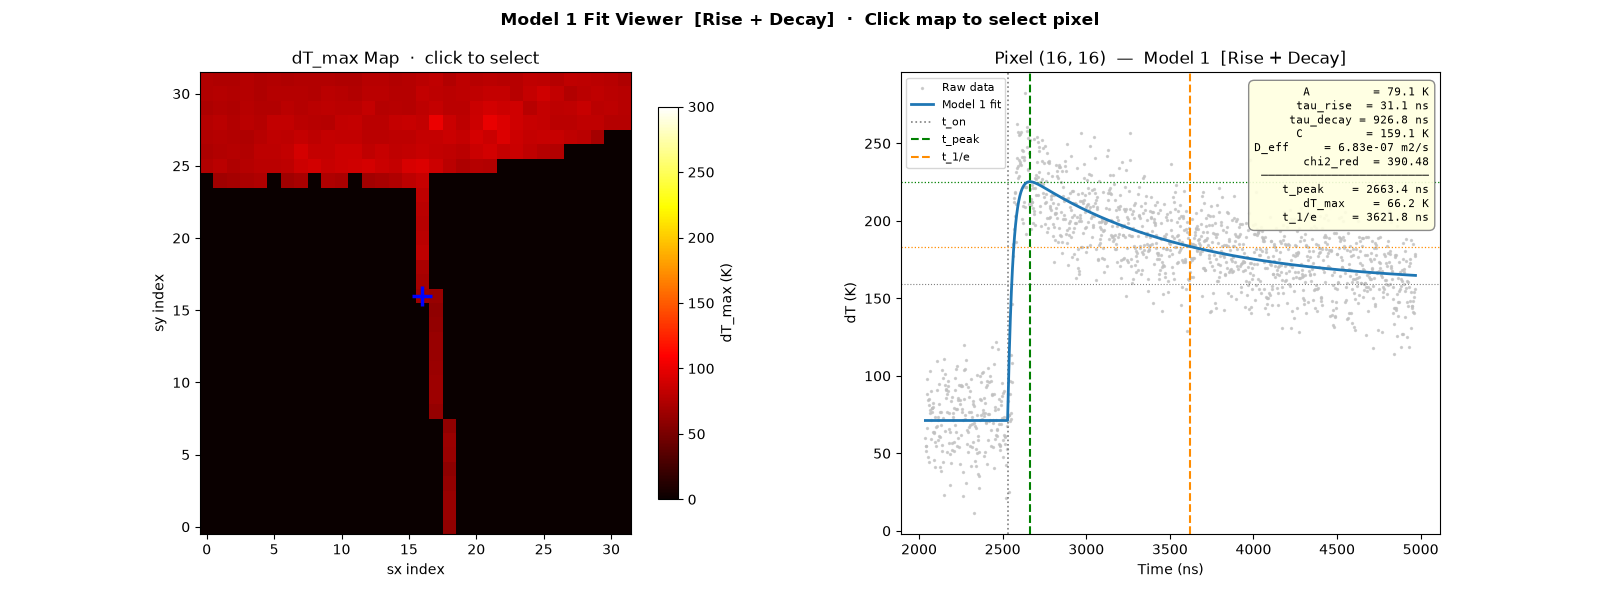

In [9]:
nav_map = param_maps['delta_T_max']

fig, (ax_map, ax_fit) = plt.subplots(1, 2, figsize=(16, 6))
mode_label = 'Rise + Decay' if fit_rise else 'Decay only'
fig.suptitle(f'Fit viewer [{mode_label}] (click the map to select a pixel)',
             fontsize=12, fontweight='bold')
plt.subplots_adjust(wspace=0.30)

# Left panel: dT_max map with a cursor for the selected pixel
im = ax_map.imshow(nav_map.T, origin='lower', cmap='hot', aspect='auto',vmax=300)
plt.colorbar(im, ax=ax_map, label='dT_max (K)', shrink=0.85)
ax_map.set_title('dT_max map')
ax_map.set_xlabel('sx index')
ax_map.set_ylabel('sy index')
cursor, = ax_map.plot([], [], 'b+', ms=14, mew=2.5, zorder=10)


def make_param_text(res):
    """Format the fitted parameters of one pixel for the annotation box."""
    sep   = '-' * 24 + '\n'
    model = res.get('model', 1)

    if model == 2:
        top = (
            f"A_1       = {res['A_1']:.1f} K\n"
            f"A_2       = {res['A_2']:.1f} K\n"
            f"tau_rise  = {res['tau_rise']:.1f} ns\n"
            f"tau_decay = {res['tau_decay']:.1f} ns\n"
            f"C         = {res['C']:.1f} K\n"
            f"chi2_red  = {res['chi2_red']:.2f}\n" + sep
        )
    elif model == 1:
        top = (
            f"A         = {res['A']:.1f} K\n"
            + (f"tau_rise  = {res['tau_rise']:.1f} ns\n" if res['tau_rise'] is not None else '')
            + f"tau_decay = {res['tau_decay']:.1f} ns\n"
            f"C         = {res['C']:.1f} K\n"
            f"chi2_red  = {res['chi2_red']:.2f}\n" + sep
        )
    else:   # decay only
        top = (
            f"A         = {res['A']:.1f} K\n"
            f"tau_decay = {res['tau_decay']:.1f} ns\n"
            f"C         = {res['C']:.1f} K\n"
            f"chi2_red  = {res['chi2_red']:.2f}\n" + sep
        )

    bottom = (
        f"t_peak    = {res['t_peak']:.1f} ns\n"
        f"dT_max    = {res['delta_T_max']:.1f} K\n"
        f"t_1/e     = {res['t_1e']:.1f} ns"
    )
    return top + bottom


def update(sx_i, sy_i):
    """Redraw fit panel for the selected pixel."""
    res     = fit_results[(sx_i, sy_i)]
    profile = data[sx_i, sy_i, :]

    cursor.set_data([sx_i], [sy_i])
    ax_fit.cla()
    ax_fit.set_xlabel('Time (ns)')
    ax_fit.set_ylabel('dT (K)')
    ax_fit.set_title(f'Pixel ({sx_i}, {sy_i})  [{mode_label}]')

    ax_fit.scatter(t_axis, profile, s=2, color='silver', alpha=0.7,
                   label='Raw data', zorder=1)

    if res['success']:
        tp    = res['t_peak']
        t1e   = res['t_1e']
        dTmax = res['delta_T_max']
        base  = res['C']

        ax_fit.plot(t_axis, res['fit'], color='tab:blue', lw=2.0,
                    label='Fit', zorder=5)

        # Markers: t_on, t_peak, t_1/e and the matching levels
        ax_fit.axvline(t_on_ns, color='gray',      ls=':',  lw=1.2, label='t_on')
        ax_fit.axvline(tp,      color='green',      ls='--', lw=1.5, label='t_peak')
        if np.isfinite(t1e):
            ax_fit.axvline(t1e, color='darkorange', ls='--', lw=1.5, label='t_1/e')

        ax_fit.axhline(base + dTmax,      color='green',      ls=':', lw=0.9)
        ax_fit.axhline(base + dTmax/np.e, color='darkorange', ls=':', lw=0.9)
        ax_fit.axhline(base,              color='gray',        ls=':', lw=0.8)

        ax_fit.text(0.98, 0.97, make_param_text(res),
                    transform=ax_fit.transAxes, va='top', ha='right',
                    fontsize=8, family='monospace',
                    bbox=dict(boxstyle='round,pad=0.5',
                              facecolor='lightyellow',
                              edgecolor='gray', alpha=0.9))
    else:
        ax_fit.text(0.5, 0.5, f"FIT FAILED\n{res['error']}",
                    transform=ax_fit.transAxes, ha='center', va='center',
                    color='red', fontsize=10)

    ax_fit.legend(fontsize=8, loc='upper left', framealpha=0.8)
    fig.canvas.draw_idle()


def on_click(event):
    """Select the clicked pixel on the map (left mouse button)."""
    if event.inaxes is ax_map and event.button == 1:
        xi = int(np.clip(round(event.xdata), 0, n_sx - 1))
        yi = int(np.clip(round(event.ydata), 0, n_sy - 1))
        update(xi, yi)


fig.canvas.mpl_connect('button_press_event', on_click)
update(n_sx // 2, n_sy // 2)    # start at the centre pixel
plt.show()

## Save and load

Saves all results, so a later session can reload them without re-fitting. The fit mode (`fit_rise`) is saved with the results.<br>
In a fresh session: run Setup, then the load cell, then the Interactive viewer.

In [ ]:
# Save fit results, parameter maps, data and time axis
with open('model1_fit_results.pkl', 'wb') as f:
    pickle.dump({
        'fit_results': fit_results,
        'param_maps' : param_maps,
        'fit_rise'   : fit_rise,
    }, f)

np.save('model1_data.npy',   data)
np.save('model1_t_axis.npy', t_axis)
np.save('model1_config.npy', np.array([t_on_ns, n_sx, n_sy, n_t]))
print('Saved.')

In [ ]:
# Load in a fresh session (run Setup first), then go to the Interactive viewer
with open('model1_fit_results.pkl', 'rb') as f:
    saved = pickle.load(f)

fit_results = saved['fit_results']
param_maps  = saved['param_maps']
fit_rise    = saved['fit_rise']
data        = np.load('model1_data.npy')
t_axis      = np.load('model1_t_axis.npy')
cfg         = np.load('model1_config.npy')
t_on_ns, n_sx, n_sy, n_t = cfg[0], int(cfg[1]), int(cfg[2]), int(cfg[3])

print(f'Loaded {len(fit_results)} pixel results.')
print(f'Fit mode : {"Rise + Decay" if fit_rise else "Decay only"}')
print(f'Available maps: {list(param_maps.keys())}')